# COMP8410 Assignment 1 — Advanced AI Model Evaluation

**Organisation:** Adobe Inc.  
**Application:** Adobe Express  
**Student ID:** 48930164

## Project Overview

This assignment evaluates two proposed AI systems for Adobe Express, focusing on the application of advanced artificial intelligence techniques to creative design and content production.

The study compares four pairs of AI models across four tasks: image–text retrieval, generative image editing, multimodal visual understanding, and agentic content generation.

Each pair represents two competing approaches to the same task. The models are evaluated independently using suitable datasets, consistent experimental conditions, quantitative metrics, qualitative observations, and analysis of their underlying AI techniques.

The experiments aim to determine not only which models achieve better performance, but also why their architectures differ, how reliably they perform, and whether they offer practical benefits for Adobe Express.

### Proposed AI Systems

- **System A:** MetaCLIP 2, Qwen-Image-Edit-2511, Qwen3-VL, and Qwen3.
- **System B:** SigLIP 2, FLUX.2 Klein, Gemma 3, and GPT-OSS.

These represent hypothetical alternatives for Adobe Express rather than claims about Adobe's existing internal systems.

### Evaluation Approach

Each experiment follows a common methodology:

1. Define the business objective and research question.
2. Select and examine an appropriate benchmark dataset.
3. Establish evaluation metrics and a baseline.
4. Evaluate both models under comparable conditions.
5. Analyse quantitative results and qualitative failures.
6. Investigate possible improvements.
7. Assess business suitability, governance, and limitations.
8. Provide a justified model recommendation.

The four experiments are documented in separate Jupyter notebooks, with the overall findings consolidated in a unified evaluation report.

The evaluation emphasises AI modelling and technical evidence rather than general software implementation. Models are compared within their respective tasks; performance scores from unrelated tasks are not directly ranked against one another.

## Experiment 1 — Image–Text Retrieval


Adobe Express supports the creation of promotional content, presentations, and digital designs. An intelligent asset retrieval system could help users locate relevant images using natural-language descriptions.

This experiment investigates whether recent vision-language representation models can improve the accuracy and efficiency of semantic image retrieval.

### 1.2 Selected Models

**Model A — MetaCLIP 2**
- Checkpoint: `facebook/metaclip-2-worldwide-b16`
- Technique: Contrastive image–text representation learning.

**Model B — SigLIP 2 Large**
- Checkpoint: `google/siglip2-large-patch16-256`
- Technique: Sigmoid-based image–text alignment and representation learning.

Both models encode images and text into feature representations that can be compared to rank images according to their relevance to a query.

### 1.3 Research Question

Which model provides more accurate semantic image retrieval while maintaining reasonable computational efficiency?



### 1.5 Dataset — Flickr8k

**Source:** https://huggingface.co/datasets/intro/flickr8k

Flickr8k contains 8,000 photographs, each associated with five human-written captions. The known image–caption relationships provide ground truth for evaluating semantic image retrieval.

The dataset was selected because it supports standard retrieval metrics, including Recall@1, Recall@5, and Recall@10, and provides predefined training, development, and test splits.

The development split will be used to establish the evaluation procedure, while the held-out test split will be reserved for the final comparison.

Although the images are general photographs rather than professional design assets, the dataset offers a reproducible benchmark for an image-search capability relevant to Adobe Express.

In [1]:
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from datasets import load_dataset
from PIL import Image
from IPython.display import display

# Shared random seed for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Inference device
device = "mps" if torch.backends.mps.is_available() else "cpu"

/opt/anaconda3/envs/comp8410-adobe/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import os

# Bypass the Xet download mechanism that caused the error.
os.environ["HF_HUB_DISABLE_XET"] = "1"

from datasets import load_dataset
import pandas as pd
from IPython.display import display

# Load only the development and test splits from Parquet files.
base_url = (
    "https://huggingface.co/datasets/intro/flickr8k/"
    "resolve/refs%2Fconvert%2Fparquet/default"
)

flickr8k = load_dataset(
    "parquet",
    data_files={
        "dev": f"{base_url}/dev/0000.parquet",
        "test": f"{base_url}/test/0000.parquet"
    }
)

dev_data = flickr8k["dev"]
test_data = flickr8k["test"]

split_summary = pd.DataFrame({
    "Split": ["Development", "Test"],
    "Images": [len(dev_data), len(test_data)]
})

display(split_summary)
print("Dataset columns:", dev_data.column_names)

Generating dev split: 1000 examples [00:00, 18621.16 examples/s]
Generating test split: 1000 examples [00:00, 15148.73 examples/s]


,Split,Images
0,Development,1000
1,Test,1000


Dataset columns: ['image', 'split', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4']


### 1.6 Ground-Truth Preparation

The Flickr8k development split contains 1,000 images, each associated
with five human-written captions.

For text-to-image retrieval, each caption is treated as an independent
text query, while its corresponding image is the ground-truth match.

This produces 5,000 text queries and 1,000 candidate images.

Both MetaCLIP 2 and SigLIP 2 will rank the same candidate images for
each query. Retrieval accuracy will be measured using Recall@1,
Recall@5, and Recall@10.

The development split is used to establish the evaluation methodology.
The test split is reserved for the final independent comparison.

In [3]:
# Prepare ground-truth text queries from the development split.

dev_queries = pd.DataFrame([
    {
        "image_id": image_id,
        "caption_id": caption_id,
        "query": caption
    }
    for caption_id in range(5)
    for image_id, caption in enumerate(
        dev_data[f"caption_{caption_id}"]
    )
])

print(f"Candidate images: {len(dev_data):,}")
print(f"Text queries: {len(dev_queries):,}")
print(f"Unique ground-truth images: {dev_queries['image_id'].nunique():,}")

display(dev_queries.head(10))

Candidate images: 1,000
Text queries: 5,000
Unique ground-truth images: 1,000


,image_id,caption_id,query
0,0,0,A child and a woman are at waters edge in a bi...
1,1,0,A boy with a stick kneeling in front of a goal...
2,2,0,A woman crouches near three dogs in a field .
3,3,0,A boy bites hard into a treat while he sits ou...
4,4,0,A person eats takeout while watching a small t...
5,5,0,The children are playing in the water .
6,6,0,A group of eight people are gathered around a ...
7,7,0,A boy in blue shorts slides down a slide into ...
8,8,0,A man in a wetsuit is throwing a baby wearing ...
9,9,0,A family playing on a tractor on a beautiful day


### 1.7 Evaluation Metrics and Baseline

The experiment evaluates text-to-image retrieval using three standard metrics:

- **Recall@1 (R@1):** Percentage of queries where the correct image is ranked first.
- **Recall@5 (R@5):** Percentage of queries where the correct image appears among the top five results.
- **Recall@10 (R@10):** Percentage of queries where the correct image appears among the top ten results.

Higher Recall@K indicates better retrieval performance.

A random-ranking baseline is established to provide a reference for the two pretrained models.

With 1,000 candidate images, the expected random Recall@1, Recall@5, and Recall@10 values are 0.1%, 0.5%, and 1.0%, respectively.

Both models will use the same queries, candidate images, ground-truth identifiers, and evaluation metrics. Inference time will also be recorded to compare computational efficiency.

The development split is used for methodology development, while the test split is reserved for the final evaluation.


In [4]:
import numpy as np
import pandas as pd

def evaluate_retrieval(scores, ground_truth, ks=(1, 5, 10)):
    """
    Evaluate text-to-image retrieval.

    scores: similarity matrix [number of queries, number of images]
    ground_truth: correct image ID for each query
    """
    ground_truth = np.asarray(ground_truth)
    max_k = max(ks)

    # Rank candidate images by descending similarity.
    ranked_images = np.argsort(-scores, axis=1)[:, :max_k]

    results = {}

    for k in ks:
        correct = (
            ranked_images[:, :k] == ground_truth[:, None]
        ).any(axis=1)

        results[f"Recall@{k}"] = correct.mean() * 100

    return results


# Random-retrieval baseline
rng = np.random.default_rng(42)

random_scores = rng.random(
    (len(dev_queries), len(dev_data)),
    dtype=np.float32
)

ground_truth = dev_queries["image_id"].to_numpy()

baseline_results = evaluate_retrieval(
    random_scores,
    ground_truth
)

baseline_df = pd.DataFrame(
    [baseline_results],
    index=["Random Baseline"]
).round(2)

display(baseline_df)

,Recall@1,Recall@5,Recall@10
Random Baseline,0.02,0.64,1.36


### 1.8 Model A — MetaCLIP 2

**Model:** MetaCLIP 2 Worldwide ViT-B/16  
**Checkpoint:** `facebook/metaclip-2-worldwide-b16`

MetaCLIP 2 is a vision-language model developed by Meta. It uses contrastive learning to align image and text representations in a shared embedding space.

The model uses separate vision and text encoders to generate embeddings, allowing semantic similarity to be calculated between an image and a written description.

**Evaluation objective:** Measure how accurately MetaCLIP 2 retrieves the correct Flickr8k image for each text query.

The pretrained model is evaluated without fine-tuning. Its performance will be compared against the random baseline and SigLIP 2 using identical evaluation data.

**Governance consideration:** The selected checkpoint has a CC BY-NC 4.0 licence, which restricts commercial use.

In [6]:
from transformers import AutoProcessor, AutoModel

MODEL_A_ID = "facebook/metaclip-2-worldwide-b16"

# Download and load the pretrained model
metaclip_processor = AutoProcessor.from_pretrained(MODEL_A_ID)
metaclip_model = AutoModel.from_pretrained(MODEL_A_ID).to(device)

metaclip_model.eval()

print("MetaCLIP 2 loaded successfully.")

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 9273.20it/s]


MetaCLIP 2 loaded successfully.


### 1.9 MetaCLIP 2 — Image Feature Extraction

MetaCLIP 2 converts images into numerical feature vectors called embeddings. These embeddings represent visual information in a shared image–text feature space.

The 1,000 Flickr8k development images are processed in batches to manage memory usage.

Each embedding is normalised before similarity calculation, allowing cosine similarity to be computed using the dot product.

The extracted embeddings are saved locally after each batch to support reproducibility and recovery from interrupted executions.

The same evaluation procedure will later be applied to SigLIP 2.

In [7]:
from pathlib import Path

# Save extracted features for reuse
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

save_path = output_dir / "metaclip2_dev_images.npy"
batch_size = 16

# Resume from saved embeddings if available
saved = np.load(save_path) if save_path.exists() else None
completed = len(saved) if saved is not None else 0
embeddings = [saved] if completed else []

print(f"Images already processed: {completed:,}")

for start in range(completed, len(dev_data), batch_size):
    end = min(start + batch_size, len(dev_data))

    images = [
        dev_data[i]["image"].convert("RGB")
        for i in range(start, end)
    ]

    inputs = metaclip_processor(
        images=images,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        features = metaclip_model.get_image_features(
            **inputs
        ).pooler_output

    features = torch.nn.functional.normalize(
        features.float(), dim=-1
    )

    embeddings.append(features.cpu().numpy())

    # Save after every batch
    np.save(save_path, np.concatenate(embeddings))

    if end % 128 == 0 or end == len(dev_data):
        print(f"Processed {end:,}/{len(dev_data):,} images")

image_embeddings = np.load(save_path)

print("\nMetaCLIP 2 image embeddings saved successfully.")
print(f"Embedding shape: {image_embeddings.shape}")

Images already processed: 0
Processed 128/1,000 images
Processed 256/1,000 images
Processed 384/1,000 images
Processed 512/1,000 images
Processed 640/1,000 images
Processed 768/1,000 images
Processed 896/1,000 images
Processed 1,000/1,000 images

MetaCLIP 2 image embeddings saved successfully.
Embedding shape: (1000, 512)


### 1.10 MetaCLIP 2 — Text Feature Extraction

The 5,000 Flickr8k development captions are converted into text embeddings using MetaCLIP 2's pretrained text encoder.

Each embedding is normalised to support cosine similarity calculation with the previously extracted image embeddings.

Captions are processed in batches, and their embeddings are saved locally to avoid repeating completed inference.

The resulting image and text embeddings will be used to rank candidate images and calculate retrieval performance.


In [8]:
# Extract MetaCLIP 2 text embeddings

save_path = output_dir / "metaclip2_dev_texts.npy"
batch_size = 64

captions = dev_queries["query"].tolist()

saved = np.load(save_path) if save_path.exists() else None
completed = len(saved) if saved is not None else 0
embeddings = [saved] if completed else []

print(f"Captions already processed: {completed:,}")

for start in range(completed, len(captions), batch_size):
    end = min(start + batch_size, len(captions))

    inputs = metaclip_processor(
        text=captions[start:end],
        padding=True,
        truncation=True,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        features = metaclip_model.get_text_features(
            **inputs
        ).pooler_output

    features = torch.nn.functional.normalize(
        features.float(), dim=-1
    )

    embeddings.append(features.cpu().numpy())
    np.save(save_path, np.concatenate(embeddings))

    if end % 640 == 0 or end == len(captions):
        print(f"Processed {end:,}/{len(captions):,} captions")

text_embeddings = np.load(save_path)

print("\nMetaCLIP 2 text embeddings saved.")
print("Embedding shape:", text_embeddings.shape)

Captions already processed: 0
Processed 640/5,000 captions
Processed 1,280/5,000 captions
Processed 1,920/5,000 captions
Processed 2,560/5,000 captions
Processed 3,200/5,000 captions
Processed 3,840/5,000 captions
Processed 4,480/5,000 captions
Processed 5,000/5,000 captions

MetaCLIP 2 text embeddings saved.
Embedding shape: (5000, 512)


### 1.11 MetaCLIP 2 — Retrieval Evaluation

The image and text embeddings are compared using cosine similarity. Since both sets of embeddings have already been normalised, their dot product provides the similarity scores.

For each of the 5,000 text queries, the model ranks all 1,000 candidate images based on similarity.

Retrieval performance is evaluated using Recall@1, Recall@5, and Recall@10 and compared against the random baseline.

These development-set results provide an initial measurement of MetaCLIP 2's retrieval performance. The held-out test set will be used for the final evaluation.

In [9]:
# Calculate similarity between captions and images
similarity_scores = text_embeddings @ image_embeddings.T

# Evaluate retrieval accuracy
metaclip_results = evaluate_retrieval(
    similarity_scores,
    ground_truth
)

# Display results
print("MetaCLIP 2 — Development Results")
print("-" * 35)

for metric in ["Recall@1", "Recall@5", "Recall@10"]:
    print(f"{metric}: {metaclip_results[metric]:.2f}% "
          f"(Random: {baseline_results[metric]:.2f}%)")

# Save results for the final report
pd.DataFrame([{
    "Model": "MetaCLIP 2",
    **metaclip_results
}]).to_csv(output_dir / "metaclip2_dev_results.csv", index=False)

print("\nResults saved successfully.")

MetaCLIP 2 — Development Results
-----------------------------------
Recall@1: 62.72% (Random: 0.02%)
Recall@5: 87.00% (Random: 0.64%)
Recall@10: 93.02% (Random: 1.36%)

Results saved successfully.


### 1.12 Initial Results and Interpretation

MetaCLIP 2 achieved Recall@1 of 62.72%, Recall@5 of 87.00%, and Recall@10 of 93.02% on 5,000 Flickr8k development queries against 1,000 candidate images.

Performance substantially exceeded the random-ranking baseline, demonstrating that the model learned useful image–text relationships.

However, 37.28% of queries did not retrieve the correct image at rank one. Further error analysis is needed to identify difficult descriptions, ambiguous images, and potential retrieval limitations.

These findings are preliminary. The final model comparison will use the held-out test split and identical evaluation settings for SigLIP 2.


### 1.13 Model B — SigLIP 2

**Model:** SigLIP 2 Large  
**Checkpoint:** `google/siglip2-large-patch16-256`  
**Developer:** Google DeepMind

SigLIP 2 is a vision-language model that aligns image and text representations using sigmoid-based learning objectives, alongside additional representation-learning techniques.

Like MetaCLIP 2, it uses vision and text encoders to support semantic image retrieval. However, their training approaches differ.

**Evaluation objective:** Evaluate SigLIP 2 on the same Flickr8k development data and compare its retrieval accuracy with MetaCLIP 2.

**Governance consideration:** The checkpoint is available under the Apache 2.0 licence, providing more flexibility for commercial applications than MetaCLIP 2's non-commercial checkpoint.


In [11]:
# Release Model A from memory; its embeddings are already saved.
import gc

del metaclip_model, metaclip_processor
gc.collect()

if device == "mps":
    torch.mps.empty_cache()

# Download and load Model B
MODEL_B_ID = "google/siglip2-large-patch16-256"

siglip_processor = AutoProcessor.from_pretrained(MODEL_B_ID)
siglip_model = AutoModel.from_pretrained(MODEL_B_ID).to(device)
siglip_model.eval()

print("SigLIP 2 loaded successfully.")


[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.
Loading weights: 100%|██████████| 792/792 [00:00<00:00, 13706.88it/s]


SigLIP 2 loaded successfully.


### 1.14 SigLIP 2 — Image Feature Extraction

SigLIP 2 converts images into numerical embeddings using its pretrained vision encoder.

The same 1,000 Flickr8k development images used for MetaCLIP 2 are processed in batches to ensure a fair comparison.

The extracted features are normalised for cosine similarity and saved after each batch to prevent loss of progress if execution is interrupted.

These embeddings will later be compared with SigLIP 2 text embeddings to evaluate image retrieval accuracy.


In [12]:
# Extract SigLIP 2 image embeddings

save_path = output_dir / "siglip2_dev_images.npy"
batch_size = 16

# Resume if embeddings have already been saved
saved = np.load(save_path) if save_path.exists() else None
completed = len(saved) if saved is not None else 0
embeddings = [saved] if completed else []

print(f"Images already processed: {completed:,}")

for start in range(completed, len(dev_data), batch_size):
    end = min(start + batch_size, len(dev_data))

    images = [
        dev_data[i]["image"].convert("RGB")
        for i in range(start, end)
    ]

    inputs = siglip_processor(
        images=images,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        features = siglip_model.get_image_features(
            **inputs
        ).pooler_output

    features = torch.nn.functional.normalize(
        features.float(), dim=-1
    )

    embeddings.append(features.cpu().numpy())

    # Save after each batch
    np.save(save_path, np.concatenate(embeddings, axis=0))

    if end % 128 == 0 or end == len(dev_data):
        print(f"Processed {end:,}/{len(dev_data):,} images")

siglip_image_embeddings = np.load(save_path)

print("\nSigLIP 2 image embeddings saved.")
print("Embedding shape:", siglip_image_embeddings.shape)

Images already processed: 0
Processed 128/1,000 images
Processed 256/1,000 images
Processed 384/1,000 images
Processed 512/1,000 images
Processed 640/1,000 images
Processed 768/1,000 images
Processed 896/1,000 images
Processed 1,000/1,000 images

SigLIP 2 image embeddings saved.
Embedding shape: (1000, 1024)


### 1.15 SigLIP 2 — Text Feature Extraction

SigLIP 2 converts natural-language descriptions into numerical embeddings using its pretrained text encoder.

The same 5,000 Flickr8k development captions used for MetaCLIP 2 are processed in batches to ensure a fair comparison.

The model's text preprocessing is applied using its official processor. The resulting embeddings are normalised for cosine similarity and saved locally to avoid repeating inference.

These embeddings will be compared with the previously extracted SigLIP 2 image embeddings to calculate Recall@1, Recall@5, and Recall@10.


In [14]:
# Extract SigLIP 2 text embeddings

save_path = output_dir / "siglip2_dev_texts.npy"
batch_size = 64
captions = dev_queries["query"].tolist()

# Resume from saved embeddings if available
saved = np.load(save_path) if save_path.exists() else None
completed = len(saved) if saved is not None else 0
embeddings = [saved] if completed else []

print(f"Captions already processed: {completed:,}")

for start in range(completed, len(captions), batch_size):
    end = min(start + batch_size, len(captions))

    inputs = siglip_processor(
        text=captions[start:end],
        padding="max_length",
        truncation=True,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        features = siglip_model.get_text_features(
            **inputs
        ).pooler_output

    features = torch.nn.functional.normalize(
        features.float(), dim=-1
    )

    embeddings.append(features.cpu().numpy())

    # Save progress after each batch
    np.save(save_path, np.concatenate(embeddings, axis=0))

    if end % 640 == 0 or end == len(captions):
        print(f"Processed {end:,}/{len(captions):,} captions")

siglip_text_embeddings = np.load(save_path)

print("\nSigLIP 2 text embeddings saved.")
print("Embedding shape:", siglip_text_embeddings.shape)

Captions already processed: 0
Processed 640/5,000 captions
Processed 1,280/5,000 captions
Processed 1,920/5,000 captions
Processed 2,560/5,000 captions
Processed 3,200/5,000 captions
Processed 3,840/5,000 captions
Processed 4,480/5,000 captions
Processed 5,000/5,000 captions

SigLIP 2 text embeddings saved.
Embedding shape: (5000, 1024)


### 1.16 SigLIP 2 — Retrieval Evaluation and Comparison

SigLIP 2's image and text embeddings are compared using cosine similarity to rank candidate images for each text query.

Recall@1, Recall@5, and Recall@10 are calculated using the same ground-truth labels and evaluation procedure applied to MetaCLIP 2.

The results are compared against MetaCLIP 2 and the random retrieval baseline to identify differences in retrieval accuracy.

These results are based on the Flickr8k development split. The held-out test split will be used for the final independent evaluation.


In [15]:
# Calculate SigLIP 2 retrieval accuracy
siglip_scores = siglip_text_embeddings @ siglip_image_embeddings.T

siglip_results = evaluate_retrieval(
    siglip_scores,
    ground_truth
)

# Compare both models against the baseline
results = {
    "Random Baseline": baseline_results,
    "MetaCLIP 2": metaclip_results,
    "SigLIP 2": siglip_results
}

print("Flickr8k Development Results")
print("-" * 40)

for model, metrics in results.items():
    print(f"\n{model}")
    for metric, value in metrics.items():
        print(f"  {metric}: {value:.2f}%")

# Save the comparison for the report
comparison_df = pd.DataFrame(results).T
comparison_df.to_csv(output_dir / "retrieval_dev_comparison.csv")

print("\nComparison saved successfully.")

Flickr8k Development Results
----------------------------------------

Random Baseline
  Recall@1: 0.02%
  Recall@5: 0.64%
  Recall@10: 1.36%

MetaCLIP 2
  Recall@1: 62.72%
  Recall@5: 87.00%
  Recall@10: 93.02%

SigLIP 2
  Recall@1: 74.18%
  Recall@5: 93.08%
  Recall@10: 96.54%

Comparison saved successfully.


### 1.17 Development Results — Comparative Analysis

Both models substantially outperformed the random retrieval baseline.

SigLIP 2 achieved higher retrieval accuracy than MetaCLIP 2 across all three metrics:

- Recall@1 improved by 11.46 percentage points.
- Recall@5 improved by 6.08 percentage points.
- Recall@10 improved by 3.52 percentage points.

The largest improvement occurred at Recall@1, which is particularly relevant to Adobe Express because users benefit when the most relevant image appears at the top of their search results.

These results suggest that SigLIP 2 is the stronger retrieval candidate on the Flickr8k development set. Further error analysis, business-specific testing, and held-out test evaluation are required before the final recommendation.

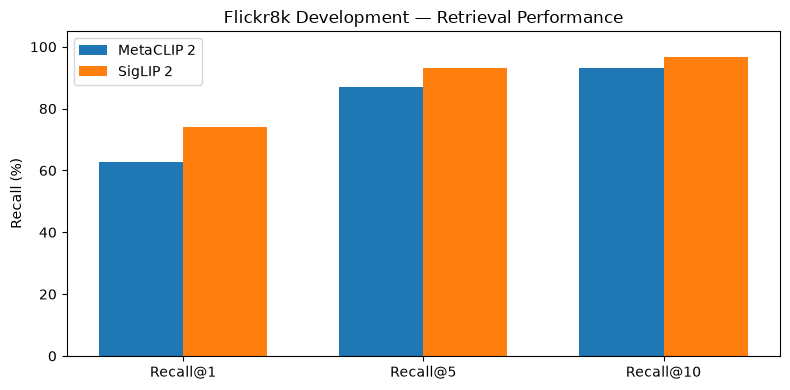

In [16]:
# Compare retrieval accuracy
metrics = ["Recall@1", "Recall@5", "Recall@10"]
x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 4))

plt.bar(x - width/2,
        [metaclip_results[m] for m in metrics],
        width, label="MetaCLIP 2")

plt.bar(x + width/2,
        [siglip_results[m] for m in metrics],
        width, label="SigLIP 2")

plt.xticks(x, metrics)
plt.ylabel("Recall (%)")
plt.ylim(0, 105)
plt.title("Flickr8k Development — Retrieval Performance")
plt.legend()
plt.tight_layout()

plt.savefig(output_dir / "retrieval_dev_comparison.png", dpi=200)
plt.show()

 Qualitative Error Analysis

Quantitative metrics measure overall retrieval accuracy but do not explain individual model failures.

This analysis examines text queries where the models produce different retrieval results.

For each example, the ground-truth image is compared with the top-ranked image from MetaCLIP 2 and SigLIP 2.

The objective is to identify whether retrieval errors involve incorrect objects, activities, visual details, or ambiguous descriptions.

A limitation of Recall@K is that a retrieved image may be semantically relevant even when it is not the annotated ground-truth image. Such cases require visual inspection before drawing conclusions.


Queries where SigLIP 2 succeeds but MetaCLIP 2 fails: 947

Query: A woman crouches near three dogs in a field .


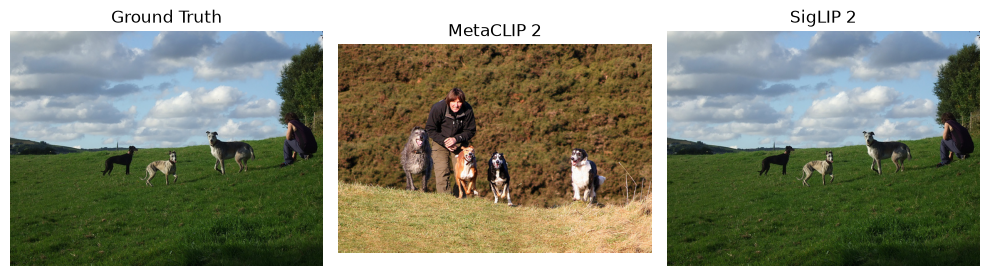


Query: A boy in blue shorts slides down a slide into a pool .


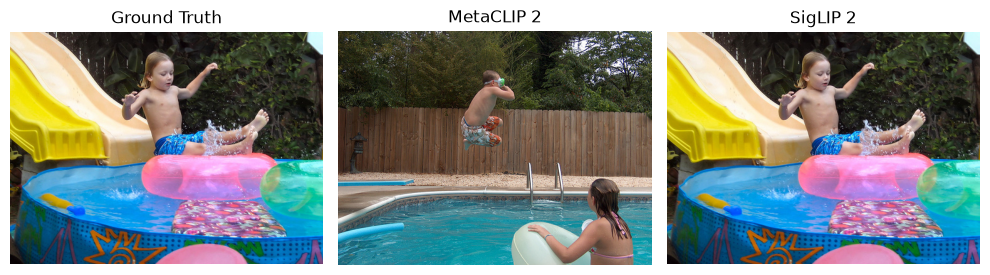

In [19]:
# Identify queries where SigLIP 2 succeeds and MetaCLIP 2 fails

meta_top1 = similarity_scores.argmax(axis=1)
siglip_top1 = siglip_scores.argmax(axis=1)

correct_images = dev_queries["image_id"].to_numpy()

# Queries where only SigLIP 2 retrieves the correct image
improved_cases = np.where(
    (siglip_top1 == correct_images) &
    (meta_top1 != correct_images)
)[0]

print(f"Queries where SigLIP 2 succeeds but MetaCLIP 2 fails: {len(improved_cases):,}")

# Show two examples
for query_id in improved_cases[:2]:
    correct_id = correct_images[query_id]

    print(f"\nQuery: {dev_queries.iloc[query_id]['query']}")

    images = [
        dev_data[int(correct_id)]["image"],
        dev_data[int(meta_top1[query_id])]["image"],
        dev_data[int(siglip_top1[query_id])]["image"]
    ]

    titles = ["Ground Truth", "MetaCLIP 2", "SigLIP 2"]

    fig, axes = plt.subplots(1, 3, figsize=(10, 3))

    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

#### Qualitative Finding — Example 1

For the query "A woman crouches near three dogs in a field", SigLIP 2 retrieved the ground-truth image at rank one, whereas MetaCLIP 2 selected a different photograph.

However, MetaCLIP 2's result also contained a woman and several dogs in an outdoor setting, making it semantically relevant despite being marked incorrect.

This highlights a limitation of Recall@K: the metric measures exact ground-truth retrieval rather than the broader usefulness of alternative images.

For Adobe Express, semantic relevance is important because users may find multiple images suitable for the same design description.


MetaCLIP 2 succeeds but SigLIP 2 fails: 374

Query: A baby girl playing at a park .


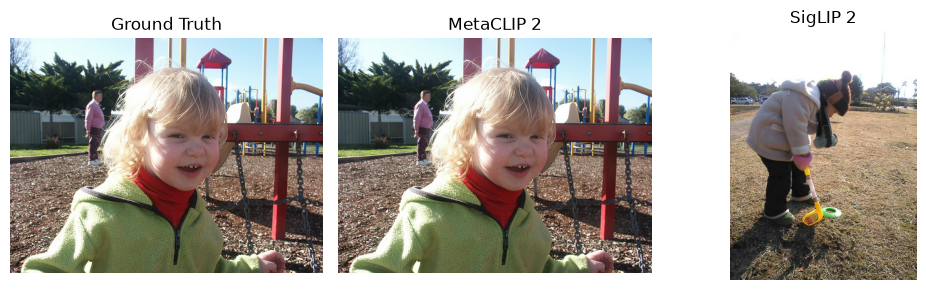

In [20]:
# Find queries where MetaCLIP 2 succeeds but SigLIP 2 fails
meta_better = np.where(
    (meta_top1 == correct_images) &
    (siglip_top1 != correct_images)
)[0]

print(f"MetaCLIP 2 succeeds but SigLIP 2 fails: {len(meta_better):,}")

# Display one example
if len(meta_better) > 0:
    query_id = meta_better[0]

    print("\nQuery:", dev_queries.iloc[query_id]["query"])

    image_ids = [
        correct_images[query_id],
        meta_top1[query_id],
        siglip_top1[query_id]
    ]

    titles = ["Ground Truth", "MetaCLIP 2", "SigLIP 2"]

    fig, axes = plt.subplots(1, 3, figsize=(10, 3))

    for ax, image_id, title in zip(axes, image_ids, titles):
        ax.imshow(dev_data[int(image_id)]["image"])
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

#### Qualitative Finding — Example 2

For the query "A baby girl playing at a park", MetaCLIP 2 retrieved the correct playground photograph, while SigLIP 2 selected a different outdoor image.

This example demonstrates that SigLIP 2's higher overall accuracy does not guarantee better performance on every query.

Across the development dataset, SigLIP 2 succeeded where MetaCLIP 2 failed on 947 queries, while MetaCLIP 2 succeeded where SigLIP 2 failed on 374 queries.

The examples also demonstrate that semantic similarity does not always correspond to exact ground-truth retrieval. Both quantitative metrics and visual inspection are therefore necessary to assess retrieval quality.
